In [1]:
# Tutorial 3 
# https://www.youtube.com/watch?v=9gBC9R-msAk


import numpy as np
from lightfm.datasets import fetch_movielens
from lightfm import LightFM
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
import matplotlib.pyplot as plt

In [2]:
#fetch data
data = fetch_movielens(min_rating=4.0)
print(type(data['item_labels']))

<class 'numpy.ndarray'>


In [3]:
#create model
model = LightFM(loss='warp')

In [4]:
#train model
model.fit(data['train'], epochs=30, num_threads=2)

In [6]:
# measure precision/recall @ k for k=1:50
test_precision = []
test_recall = []
train_precision = []
train_recall = []

for i in np.arange(1, 51):
    test_precision.append(precision_at_k(model, data['test'], train_interactions=data['train'], k=i).mean())
    test_recall.append(recall_at_k(model, data['test'], train_interactions=data['train'], k=i).mean())
    train_precision.append(precision_at_k(model, data['train'], train_interactions=data['test'], k=i).mean())
    train_recall.append(recall_at_k(model, data['train'], train_interactions=data['test'], k=i).mean())

In [7]:
auc = auc_score(model, data['test']).mean()
print(auc)

0.9179249


Text(0.5, 1.0, 'Precision-Recall Curves for Tutorial 3 MovieLens LightFM model (Remove Train Interactions)')

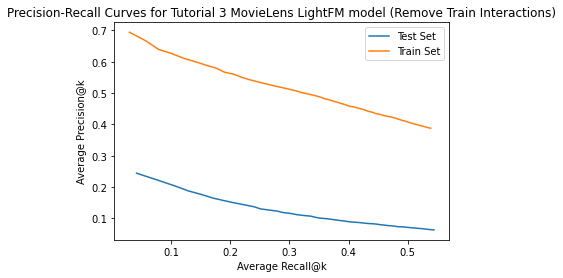

In [9]:
#Plot precision-recall curves for train and test data
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall, test_precision)
plt.plot(train_recall, train_precision)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for Tutorial 3 MovieLens LightFM model (Remove Train Interactions)')

In [11]:
def sample_recommendation(model, data, user_ids):
    
    #number of users and movies in training dataset
    n_users, n_movies = data['train'].shape
    
    #generate recommendations for each user
    for user_id in user_ids:
        
        #movies they like
        known_positives = data['item_labels'][data['train'].tocsr()[user_id].indices]
        
        #movies model predicts they will like
        scores = model.predict(user_id, np.arange(n_movies))
        print(np.argsort(scores))
        #rank from most liked to least
        top_items = data['item_labels'][np.argsort(-scores)]
        
        #print results
        print('User %s' % user_id)
        print('   Known Positives:')
        
        for x in known_positives[:3]:
            print('      %s' % x)
            
        print('   Recommended:')
        for x in top_items[:5]:
            print('      %s' % x)
            
sample_recommendation(model, data, [14, 200, 450])

[232 183 566 ... 282 285 274]
User 14
   Known Positives:
      Dead Man Walking (1995)
      Postino, Il (1994)
      Mr. Holland's Opus (1995)
   Recommended:
      Sense and Sensibility (1995)
      English Patient, The (1996)
      Emma (1996)
      Air Force One (1997)
      Secrets & Lies (1996)
[1031  931  622 ...  474   55   11]
User 200
   Known Positives:
      Get Shorty (1995)
      Seven (Se7en) (1995)
      Usual Suspects, The (1995)
   Recommended:
      Usual Suspects, The (1995)
      Pulp Fiction (1994)
      Trainspotting (1996)
      Fargo (1996)
      L.A. Confidential (1997)
[132 658 130 ... 327 287 299]
User 450
   Known Positives:
      Contact (1997)
      George of the Jungle (1997)
      Event Horizon (1997)
   Recommended:
      Air Force One (1997)
      Scream (1996)
      Conspiracy Theory (1997)
      Scream 2 (1997)
      Game, The (1997)
